# Batch 2 BLIB Pipeline
**Kinase–Substrate Interaction (KSI) Screening Analysis**

This notebook processes the 2-batch BLIB screening data, computes library coverage statistics, and benchmarks screening results against curated database annotations.

---
### Table of Contents
1. [Setup & Imports](#1-setup--imports)
2. [Helper Functions](#2-helper-functions)
3. [Load Reference Data](#3-load-reference-data)
4. [Load Screening Data](#4-load-screening-data)
5. [Library Coverage Statistics](#5-library-coverage-statistics)
6. [Database Annotation Filtering](#6-database-annotation-filtering)
7. [Confusion Matrix Analysis](#7-confusion-matrix-analysis)
8. [False Negative Inspection (PAABD)](#8-false-negative-inspection-paabd)
9. [Summary Stats Table](#9-summary-stats-table)

---
## 1. Setup & Imports

In [2]:
# Install dependencies (run once)
import subprocess
subprocess.run(['python', '-m', 'pip', 'install', 'matplotlib-venn', 'biopython'], check=True)

CompletedProcess(args=['python', '-m', 'pip', 'install', 'matplotlib-venn', 'biopython'], returncode=0)

In [3]:
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

from Bio.Seq import Seq
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from matplotlib_venn import venn2, venn3, venn3_unweighted

%matplotlib inline

# ── Paper-ready palette ────────────────────────────────────────────────────────
# 4-colour diverging palette adapted from ColorBrewer RdBu (print- & CVD-safe)
PALETTE = {
    'TP': '#2166ac',   # strong blue
    'TN': '#92c5de',   # light blue
    'FP': '#f4a582',   # light red/orange
    'FN': '#d6604d',   # medium red
    'text_light': '#ffffff',
    'text_dark':  '#1a1a1a',
}

# Build a 2×2 colour array for imshow
CM_COLORS = np.array([
    [PALETTE['TN'], PALETTE['FP']],
    [PALETTE['FN'], PALETTE['TP']],
])

plt.rcParams.update({
    'font.family':   'sans-serif',
    'font.size':     11,
    'axes.linewidth': 0.8,
    'savefig.dpi':   300,
    'savefig.bbox':  'tight',
})

print('Imports complete.')

Imports complete.


---
## 2. Helper Functions

### 2a. KS-pair key & PAABD domain assignment

**Binding domain motifs detected:**

| Domain | Motif |
|--------|-------|
| SH2    | `XXXXXXX[pY]XX[I/L/V/M]XXXX` — pY at position 0, hydrophobic at +3 |
| 14-3-3b | `XXXXRXX[pS/pT]XPXXXXX` |
| WW     | `XXXXXXX[pS/pT]PXXXXXX` |
| FHA    | `XXXXXXX[pT]XX[D]XXXX` |

In [4]:
def add_ks_pair(df):
    """Create a unique kinase–substrate pair identifier string."""
    df['ks_pair'] = (
        df['substrate_seq'].astype(str) + '-' +
        df['kinase_seq'] + '-' +
        df['p_aa'].astype(str) + '-' +
        df['p_ind'].astype(str) + '-' +
        df['kinase_coord'].astype(str)
    )
    return df


def assign_paabd(dat, train_dat=None, assign_kinase=False, get_sub_15=True):
    """
    Assign phospho-amino-acid binding domain (PAABD) flags to each substrate.

    Parameters
    ----------
    dat          : input DataFrame
    train_dat    : reference DataFrame with kinase–kinase_seq mapping (optional)
    assign_kinase: merge kinase names from train_dat
    get_sub_15   : extract 15-aa centred window from full substrate sequence
    """
    if get_sub_15:
        dat['substrate_seq_15aa'] = dat.apply(
            lambda s: s['substrate_seq'][s['p_ind'] - 1 - 7 : s['p_ind'] - 1 + 8],
            axis=1
        )
    dat = dat.loc[dat['substrate_seq_15aa'].apply(len) == 15, :]

    dat.loc[:, 'SH2']     = dat['substrate_seq_15aa'].apply(
        lambda s: (s[7] == 'Y') & (s[10] in {'I', 'L', 'V', 'M'})
    )
    dat.loc[:, 'b14-3-3'] = dat['substrate_seq_15aa'].apply(
        lambda s: ((s[7] == 'S') | (s[7] == 'T')) & (s[4] == 'R') & (s[9] == 'P')
    )
    dat.loc[:, 'WW']  = dat['substrate_seq_15aa'].apply(
        lambda s: ((s[7] == 'S') | (s[7] == 'T')) & (s[8] == 'P')
    )
    dat.loc[:, 'FHA'] = dat['substrate_seq_15aa'].apply(
        lambda s: (s[7] == 'T') & (s[10] == 'D')
    )

    if assign_kinase:
        dat = pd.merge(
            dat,
            train_dat.loc[:, ['kinase', 'kinase_seq']].drop_duplicates(),
            on='kinase_seq'
        )
    return dat

### 2b. Confusion matrix plot

In [5]:
from matplotlib import cm as mplcm
import numpy as np

# ── Summer palette sampled at 4 positions ─────────────────────────────────────
_summer = mplcm.get_cmap('summer')

CELL_VALS = {
    'TN': 0.95,   # pale yellow  – large, expected, low salience
    'FP': 0.65,   # yellow-green – moderate concern
    'FN': 0.40,   # mid-green    – moderate concern
    'TP': 0.10,   # deep green   – key result
}

def _luminance(rgba):
    """Relative luminance of an RGBA tuple (linear approximation)."""
    r, g, b = rgba[:3]
    return 0.2126 * r + 0.7152 * g + 0.0722 * b


def plot_db_vs_screening_confusion(
    curr_df,
    title='Database vs Screening Confusion Matrix',
    set_col='set',
    tn_label='train_tn',
    screening_col='true_positive',
    figsize=(5.6, 4.8),
    fname = ""
):
    """
    Plot a styled 2×2 confusion matrix using the matplotlib 'summer' colormap.

    Axes
    ----
    rows  : Database label  (- = tn_label, + = anything else)
    cols  : Screening call  (- = False, + = True in screening_col)

    Returns
    -------
    ax    : matplotlib Axes
    stats : dict with TP, FP, FN, TN, accuracy, precision, recall, cm
    """
    s         = curr_df[screening_col].astype(bool)
    is_db_neg = curr_df[set_col].eq(tn_label)
    is_db_pos = ~is_db_neg

    TP = int(( s &  is_db_pos).sum())
    FP = int(( s &  is_db_neg).sum())
    FN = int((~s &  is_db_pos).sum())
    TN = int((~s &  is_db_neg).sum())

    cm_arr = np.array([[TN, FP], [FN, TP]])

    # ── cell colours from summer cmap ─────────────────────────────────────────
    key_grid = [['TN', 'FP'], ['FN', 'TP']]
    cell_rgba = [[_summer(CELL_VALS[k]) for k in row] for row in key_grid]

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_facecolor('white')

    for i in range(2):
        for j in range(2):
            rgba = cell_rgba[i][j]
            ax.add_patch(plt.Rectangle(
                (j - 0.5, i - 0.5), 1, 1,
                color=rgba, zorder=0
            ))
            # auto text contrast: white on dark, dark on light
            text_color = 'white' if _luminance(rgba) < 0.45 else '#1a1a1a'
            cell_label = key_grid[i][j]
            ax.text(
                j, i,
                f"{cell_label}\n{cm_arr[i, j]:,}",
                ha='center', va='center',
                fontsize=13, fontweight='bold',
                color=text_color, zorder=1
            )

    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Screening −', 'Screening +'], fontsize=11)
    ax.set_yticklabels(['Database −', 'Database +'], fontsize=11)
    ax.set_xlabel('Screening', fontsize=12, labelpad=8)
    ax.set_ylabel('Database', fontsize=12, labelpad=8)
    ax.set_title(title, fontsize=13, pad=10)

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

    # ── metrics side-panel ────────────────────────────────────────────────────
    total = cm_arr.sum()
    acc   = (TP + TN) / total if total else np.nan
    prec  = TP / (TP + FP)    if (TP + FP) else np.nan
    rec   = TP / (TP + FN)    if (TP + FN) else np.nan

    metrics_txt = (
        f"n = {total:,}\n"
        f"Accuracy  {acc:.3f}\n"
        f"Precision {prec:.3f}\n"
        f"Recall    {rec:.3f}"
    )
    ax.text(
        1.04, 0.5, metrics_txt,
        transform=ax.transAxes, va='center', ha='left',
        fontsize=10, fontfamily='monospace',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f7f7f7', edgecolor='#cccccc')
    )

    plt.tight_layout()
    if fname != "":
        plt.savefig(f"./{fname}.pdf", bbox_inches='tight')
    plt.show()

    return ax, {
        'TP': TP, 'FP': FP, 'FN': FN, 'TN': TN,
        'accuracy': acc, 'precision': prec, 'recall': rec,
        'cm': cm_arr,
    }

In [6]:
def plot_db_vs_screening_confusion_evaluable(
    curr_df,
    rec_dict,
    title='Database vs Screening Confusion Matrix (Evaluable Subset)',
    set_col='set',
    tn_label='train_tn',
    screening_col='true_positive',
    figsize=(5.6, 4.8),
):
    """
    2×2 confusion matrix where the FN cell shows only EVALUABLE false negatives
    (i.e., non-evaluable FN pairs — fp_sub, inactive, no PAABD, not in screen —
    are excluded from the DB+ denominator).

    Parameters
    ----------
    curr_df  : full confusion-matrix DataFrame (used for TP / FP / TN)
    rec_dict : dict returned by evaluable_recall() — supplies FN_evaluable count
    """
    s         = curr_df[screening_col].astype(bool)
    is_db_neg = curr_df[set_col].eq(tn_label)
    is_db_pos = ~is_db_neg

    TP = int(( s &  is_db_pos).sum())
    FP = int(( s &  is_db_neg).sum())
    TN = int((~s &  is_db_neg).sum())

    # Use evaluable FN only — non-evaluable pairs excluded from denominator
    FN = rec_dict['FN_evaluable']
    FN_excluded = rec_dict['FN_total'] - FN

    cm_arr = np.array([[TN, FP], [FN, TP]])

    key_grid   = [['TN', 'FP'], ['FN', 'TP']]
    cell_rgba  = [[_summer(CELL_VALS[k]) for k in row] for row in key_grid]

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_facecolor('white')

    for i in range(2):
        for j in range(2):
            rgba = cell_rgba[i][j]
            ax.add_patch(plt.Rectangle(
                (j - 0.5, i - 0.5), 1, 1,
                color=rgba, zorder=0
            ))
            text_color = 'white' if _luminance(rgba) < 0.45 else '#1a1a1a'
            cell_label = key_grid[i][j]
            # FN cell: show evaluable count + strikethrough hint for excluded
            if cell_label == 'FN':
                label_str = (
                    f"FN\n{FN:,} (evaluable)\n"
                    f"[+{FN_excluded} excluded]"
                )
            else:
                label_str = f"{cell_label}\n{cm_arr[i, j]:,}"
            ax.text(
                j, i, label_str,
                ha='center', va='center',
                fontsize=11 if cell_label == 'FN' else 13,
                fontweight='bold',
                color=text_color, zorder=1
            )

    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Screening −', 'Screening +'], fontsize=11)
    ax.set_yticklabels(['Database −', 'Database +'], fontsize=11)
    ax.set_xlabel('Screening', fontsize=12, labelpad=8)
    ax.set_ylabel('Database', fontsize=12, labelpad=8)
    ax.set_title(title, fontsize=13, pad=10)

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

    # ── metrics side-panel ────────────────────────────────────────────────────
    total_eval = TP + FP + FN + TN
    acc   = (TP + TN) / total_eval if total_eval else np.nan
    prec  = TP / (TP + FP)         if (TP + FP)  else np.nan
    rec   = TP / (TP + FN)         if (TP + FN)  else np.nan

    metrics_txt = (
        f"n (eval.) = {total_eval:,}\n"
        f"excluded  = {FN_excluded:,}\n"
        f"coverage  = {rec_dict['db_coverage']:.3f}\n"
        f"─────────────────\n"
        f"Accuracy  {acc:.3f}\n"
        f"Precision {prec:.3f}\n"
        f"Recall    {rec:.3f}"
    )
    ax.text(
        1.04, 0.5, metrics_txt,
        transform=ax.transAxes, va='center', ha='left',
        fontsize=10, fontfamily='monospace',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f7f7f7', edgecolor='#cccccc')
    )

    # ── footnote: excluded FN categories ─────────────────────────────────────
    excluded_parts = []
    for cat in NON_EVALUABLE:
        n = rec_dict.get(f'FN_{cat}', 0)
        if n:
            excluded_parts.append(f"{CATEGORY_LABELS[cat]} (n={n})")
    if excluded_parts:
        footnote = "Excluded FN: " + ", ".join(excluded_parts)
        fig.text(0.5, -0.04, footnote, ha='center', fontsize=8,
                 color='#555555', style='italic',
                 wrap=True)

    plt.tight_layout()
    plt.show()

    return ax, {
        'TP': TP, 'FP': FP, 'FN': FN, 'TN': TN,
        'FN_excluded': FN_excluded,
        'accuracy': acc, 'precision': prec, 'recall': rec,
        'cm': cm_arr,
    }


---
## 3. Load Reference Data

In [7]:
# Human kinome reference sequences
human_kinome = pd.read_pickle('../kinase_ml/data/human_kinome_seq_230301.pkl')
print(f'Human kinome: {human_kinome.shape[0]} entries')

Human kinome: 503 entries


In [8]:
# Annotated interactions database
interaction_classed = assign_paabd(
    pd.read_pickle('../kinase_ml/data/interactions/interaction_classed_221017_wsource.pkl')
)

interaction_classed = (
    interaction_classed
    .loc[:, ['kinase', 'substrate_seq_15aa', 'source_all']]
    .drop_duplicates()
    .rename(columns={'source_all': 'source'})
)
interaction_classed['y_true'] = 1

print(f'Interaction DB: {interaction_classed.shape[0]} unique KSIs')

Interaction DB: 27746 unique KSIs


In [9]:
# Model predictions on held-out test set
test_pred_v1 = pd.read_pickle(
    os.path.join('../kinase_ml/data', 'kinbertv1_pred', 'kinbertv1_DB_Test.pkl')
)
test_pred_v1['y_pred'] = test_pred_v1['logits'].apply(lambda s: int(s[1] > s[0]))
test_pred_v1 = assign_paabd(test_pred_v1, train_dat=None, assign_kinase=False)

test_pred_v1 = (
    test_pred_v1
    .loc[:, ['kinase_seq', 'substrate_seq_15aa', 'y_true', 'y_pred', 'source']]
    .merge(human_kinome, on='kinase_seq')
    .loc[:, ['kinase', 'substrate_seq_15aa', 'source', 'y_true']]
)

# Combined annotation
data_anno = pd.concat([interaction_classed, test_pred_v1], ignore_index=True)
print(f'Combined annotation: {data_anno.shape[0]} rows')

Combined annotation: 1604720 rows


---
## 4. Load Screening Data

In [10]:
# Designed substrate sets
y_sub_all  = pd.read_csv('../kinase_ml/code/wetlab_planning/y_sub_all.csv').drop_duplicates('substrate_seq_15aa')
st_sub_all = pd.read_csv('../kinase_ml/code/wetlab_planning/st_sub_all.csv').drop_duplicates('substrate_seq_15aa')

y_sub_all['p_aa']  = 'Y'
st_sub_all['p_aa'] = st_sub_all['substrate_seq_15aa'].apply(lambda s: s[7])

sty_sub_df = pd.concat([st_sub_all, y_sub_all], ignore_index=True)
print(f'Y substrates: {y_sub_all.shape[0]}  |  ST substrates: {st_sub_all.shape[0]}')

Y substrates: 1950  |  ST substrates: 1978


In [11]:
# Spike-in controls
y_spike_ins  = pd.read_csv('../kinase_ml/code/wetlab_planning/y_spike_ins.csv') .drop_duplicates('substrate_seq_15aa').iloc[:, 1:]
st_spike_ins = pd.read_csv('../kinase_ml/code/wetlab_planning/st_spike_ins.csv').drop_duplicates('substrate_seq_15aa').iloc[:, 1:]
sty_spike_ins = pd.concat([st_spike_ins, y_spike_ins], ignore_index=True)

In [12]:
# BLIB kinase list with accessions
blib_kinases_with_acc = pd.read_csv('../screening_analysis/blib_kinases_with_acc.csv', header=None)
blib_kinases_with_acc.columns = ['kinase_type', 'kinase', 'kinase_seq', 'kinase_acc']

# Lookup tables (sanitized)
y_lookup_sanitized  = pd.read_pickle('./lookup_tables/y.lookup.corrected.pkl')
st_lookup_sanitized = pd.read_pickle('./lookup_tables/st.lookup.corrected.pkl')

# Raw KSI screening table (2-batch merged, deduplicated)
ksi_df = pd.read_pickle('./dat_all_blib_2batch.pkl').drop_duplicates(['substrate_aa', 'kinase_aa'])
ksi_df = ksi_df.drop(['substrate'], axis=1)
ksi_df.columns = [
    'id', 'num', 'neg|score', 'neg|p-value', 'neg|fdr', 'neg|rank',
    'neg|goodsgrna', 'neg|lfc', 'pos|score', 'pos|p-value', 'pos|fdr',
    'pos|rank', 'pos|goodsgrna', 'pos|lfc', 'sgrna', 'Gene',
    'control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC',
    'control_var', 'adj_var', 'score', 'p.low', 'p.high', 'p.twosided',
    'FDR', 'high_in_treatment', 'identifier', 'length', 'seq',
    'barcode_seq', 'ksregion', 'kinase', 'substrate',
    'kinase_seq', 'kinase_type', 'kinase_name', 'kinase_acc', 'paabd',
    'pre_1', 'mtx_1', 'pre_2', 'mtx_2'
]

ksi_df_y  = ksi_df.loc[ksi_df['kinase_type'] == 'Y', :]
ksi_df_st = ksi_df.loc[ksi_df['kinase_type'] != 'Y', :]

print(f'KSI table — Y: {ksi_df_y.shape[0]}  ST: {ksi_df_st.shape[0]}')

KSI table — Y: 13943  ST: 23452


---
## 5. Library Coverage Statistics

In [13]:
sty_spike_ins.loc[sty_spike_ins['set']=='train_pos',:]

,substrate_seq_15aa,kinase,logit,PAABD,p_aa,set
373,RPLSRTQSSPLPQSP,Q8N5S9,3.758889,b14-3-3,S,train_pos
374,VPSCSASSCSSVTAS,Q8N5S9,3.487501,FHA,S,train_pos
375,DRGQAYATEWSDDES,Q8N5S9,2.301646,FHA,S,train_pos
376,ENVGKVGSPLDYSLV,P53350,3.812164,WW,S,train_pos
377,DTQGRNSTPLHLAAG,P53350,3.779714,WW,S,train_pos
...,...,...,...,...,...,...
611,AQAFPVSYSSSGARR,P07949,2.450374,SH2,Y,train_pos
612,TPSDSLIYDDGLSEE,P07949,2.404736,SH2,Y,train_pos
613,SSSSDEEYIYMNKVT,P07949,2.369053,SH2,Y,train_pos
614,ARTTSQLYDAVPIQS,P07949,2.186530,SH2,Y,train_pos


In [14]:
ksi_df_st['kinase_name'].unique()

array(['MAST1_HUMAN', 'ADCK1_HUMAN', 'PDPK1_HUMAN', 'PHKG1_HUMAN',
       'KS6B1_HUMAN_wt', 'TITIN_HUMAN', 'KGP1_HUMAN', 'KKCC1_HUMAN',
       'PLK1_HUMAN_active', 'PLK1_HUMAN', 'M3K7_HUMAN', 'TBK1_HUMAN',
       'IKKB_HUMAN', 'KS6B1_HUMAN_active', 'PIM1_HUMAN'], dtype=object)

In [15]:
# ── Substrates ────────────────────────────────────────────────────────────────
nsub_y_design = y_sub_all.shape[0]
nsub_y_ecoli  = int(y_lookup_sanitized['substrate_aa'].drop_duplicates().isin(y_sub_all['substrate_seq_15aa']).sum())
nsub_y_yeast  = int(ksi_df_y['substrate'].drop_duplicates().isin(y_sub_all['substrate_seq_15aa']).sum())

nsub_st_design = st_sub_all.shape[0]
nsub_st_ecoli  = int(st_lookup_sanitized['substrate_aa'].drop_duplicates().isin(st_sub_all['substrate_seq_15aa']).sum())
nsub_st_yeast  = int(ksi_df_st['substrate'].drop_duplicates().isin(st_sub_all['substrate_seq_15aa']).sum())

n_kinase_y = ksi_df_y['kinase_name'].unique().shape[0]
n_kinase_st = ksi_df_st['kinase_name'].unique().shape[0]


# ----- KSIs -----
designed_ks_y = [
    s + '&' + k
    for s in y_sub_all['substrate_seq_15aa'].tolist()
    for k in blib_kinases_with_acc.loc[blib_kinases_with_acc['kinase_type'] == 'Y', 'kinase_seq'].tolist()
]
ecoli_ks_y = set(y_lookup_sanitized['substrate_aa'] + '&' + y_lookup_sanitized['kinase_aa']).intersection(designed_ks_y)
yeast_ks_y = set(ksi_df_y['substrate'] + '&' + ksi_df_y['kinase_seq']).intersection(designed_ks_y)

designed_ks_st = [
    s + '&' + k
    for s in st_sub_all['substrate_seq_15aa'].tolist()
    for k in ksi_df_st.loc[ksi_df_st['kinase_type'] == 'ST', 'kinase_seq'].drop_duplicates().tolist()
]
ecoli_ks_st = set(st_lookup_sanitized['substrate_aa'] + '&' + st_lookup_sanitized['kinase_aa']).intersection(designed_ks_st)
yeast_ks_st = set(ksi_df_st['substrate'] + '&' + ksi_df_st['kinase_seq']).intersection(designed_ks_st)

# ----- stats table -----
stats_df = pd.DataFrame(
    {
        "n_substrate_designed":        [nsub_y_design,  nsub_st_design],
        'n_kinase': [n_kinase_y,n_kinase_st],
        "n_substrate_ecoli_constructed":[nsub_y_ecoli,  nsub_st_ecoli],
        "n_substrate_yeast_screened":  [nsub_y_yeast,   nsub_st_yeast],
        "n_ksi_designed":              [len(designed_ks_y), len(designed_ks_st)],
        "n_ksi_ecoli_constructed":     [len(ecoli_ks_y),    len(ecoli_ks_st)],
        "n_ksi_yeast_screened":        [len(yeast_ks_y),    len(yeast_ks_st)],
    },
    index=["Y library", "ST library"],
).reset_index(names="library")

stats_df

,library,n_substrate_designed,n_kinase,n_substrate_ecoli_constructed,n_substrate_yeast_screened,n_ksi_designed,n_ksi_ecoli_constructed,n_ksi_yeast_screened
0,Y library,1950,8,1939,1932,15600,14873,13220
1,ST library,1978,15,1968,1964,29670,25214,22695


In [16]:
stats_df.to_latex()

'\\begin{tabular}{llrrrrrrr}\n\\toprule\n & library & n_substrate_designed & n_kinase & n_substrate_ecoli_constructed & n_substrate_yeast_screened & n_ksi_designed & n_ksi_ecoli_constructed & n_ksi_yeast_screened \\\\\n\\midrule\n0 & Y library & 1950 & 8 & 1939 & 1932 & 15600 & 14873 & 13220 \\\\\n1 & ST library & 1978 & 15 & 1968 & 1964 & 29670 & 25214 & 22695 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [17]:
ksi_df_y['substrate'].drop_duplicates().apply(lambda s: s[7]=='Y').sum()

np.int64(2553)

In [18]:
(ksi_df_y.groupby(['substrate']).count().sort_values('identifier')['id']>1).sum()

np.int64(1931)

In [19]:
(ksi_df_st.groupby(['substrate']).count().sort_values('identifier')['id']>1).sum()

np.int64(1949)

In [20]:
y_kinase_seqs = ksi_df_y.loc[ksi_df_y['kinase_type'] == 'Y', 'kinase_seq'].drop_duplicates().tolist()
st_kinase_seqs = ksi_df_st.loc[ksi_df_st['kinase_type'] == 'ST', 'kinase_seq'].drop_duplicates().tolist()
y_lookup_sanitized = y_lookup_sanitized.loc[y_lookup_sanitized['kinase_aa'].isin(y_kinase_seqs),:]
st_lookup_sanitized = st_lookup_sanitized.loc[st_lookup_sanitized['kinase_aa'].isin(st_kinase_seqs),:]

# ── Substrates ────────────────────────────────────────────────────────────────
nsub_y_design = y_sub_all.shape[0]
nsub_y_ecoli  = int(y_lookup_sanitized['substrate_aa'].drop_duplicates().isin(y_sub_all['substrate_seq_15aa']).sum())
nsub_y_yeast  = int(ksi_df_y['substrate'].drop_duplicates().isin(y_sub_all['substrate_seq_15aa']).sum())

nsub_st_design = st_sub_all.shape[0]
nsub_st_ecoli  = int(st_lookup_sanitized['substrate_aa'].drop_duplicates().isin(st_sub_all['substrate_seq_15aa']).sum())
nsub_st_yeast  = int(ksi_df_st['substrate'].drop_duplicates().isin(st_sub_all['substrate_seq_15aa']).sum())

n_kinase_y = ksi_df_y['kinase_name'].unique().shape[0]
n_kinase_st = ksi_df_st['kinase_name'].unique().shape[0]


# ----- KSIs -----
designed_ks_y = [
    s + '&' + k
    for s in y_sub_all['substrate_seq_15aa'].tolist()
    for k in blib_kinases_with_acc.loc[blib_kinases_with_acc['kinase_type'] == 'Y', 'kinase_seq'].tolist()
]



ecoli_ks_y = set(y_lookup_sanitized['substrate_aa'] + '&' + y_lookup_sanitized['kinase_aa'])
yeast_ks_y = set(ksi_df_y['substrate'] + '&' + ksi_df_y['kinase_seq'])

designed_ks_st = [
    s + '&' + k
    for s in st_sub_all['substrate_seq_15aa'].tolist()
    for k in ksi_df_st.loc[ksi_df_st['kinase_type'] == 'ST', 'kinase_seq'].drop_duplicates().tolist()
]
ecoli_ks_st = set(st_lookup_sanitized['substrate_aa'] + '&' + st_lookup_sanitized['kinase_aa'])
yeast_ks_st = set(ksi_df_st['substrate'] + '&' + ksi_df_st['kinase_seq'])

# ----- stats table -----
stats_df = pd.DataFrame(
    {
        'n_kinase': [n_kinase_y,n_kinase_st],

        "n_substrate_yeast_screened":  [nsub_y_yeast,   nsub_st_yeast],

        "n_ksi_yeast_screened":        [len(yeast_ks_y),    len(yeast_ks_st)],
    },
    index=["Y library", "ST library"],
).reset_index(names="library")

# including substrates not in the design
stats_df

,library,n_kinase,n_substrate_yeast_screened,n_ksi_yeast_screened
0,Y library,8,1932,13943
1,ST library,15,1964,23452


In [21]:
stats_df.columns = ['library','#n kinase','#n substrate','#n KSIs']

In [22]:
stats_df.to_latex()

'\\begin{tabular}{llrrr}\n\\toprule\n & library & #n kinase & #n substrate & #n KSIs \\\\\n\\midrule\n0 & Y library & 8 & 1932 & 13943 \\\\\n1 & ST library & 15 & 1964 & 23452 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [23]:
st_lookup_sanitized.groupby('kinase_aa').count().reset_index().sort_values('identifier')

,kinase_aa,identifier,length,seq,barcode_seq,ksregion,substrate,kinase,substrate_aa,kinase_type,kinase_name,kinase_acc
11,YMIAEDLGRGEFGIVHRCVETSSKKTYMAKFVKVKGTDQVLVKKEI...,1805,1805,1805,1805,1805,1805,1805,1805,1805,1805,1805
8,WLLSDILGQGATANVFRGRHKKTGDLFAIKVFNNISFLRPVDVQMR...,2977,2977,2977,2977,2977,2977,2977,2977,2977,2977,2977
7,WEMKERLGTGGFGNVIRWHNQETGEQIAIKQCRQELSPRNRERWCL...,3111,3111,3111,3111,3111,3111,3111,3111,3111,3111,3111
6,SFDDTPLGTASLAQVHKAVLHDGRTVAVKVQHPKVRAQSSKDILLM...,3583,3583,3583,3583,3583,3583,3583,3583,3583,3583,3583
5,IEVEEVVGRGAFGVVCKAKWRAKDVAIKQIESESERKAFIVELRQL...,3863,3863,3863,3863,3863,3863,3863,3863,3863,3863,3863
2,FELLRVLGKGGYGKVFQVRKVTGANTGKIFAMKVLKKAMIVRNAKD...,4768,4768,4768,4768,4768,4768,4768,4768,4768,4768,4768
3,FKFGKILGEGSFSTVVLARELATSREYAIKILEKRHIIKENKVPYV...,5422,5422,5422,5422,5422,5422,5422,5422,5422,5422,5422
1,FELLRVLGKGGYGKVFQVRKVTGANTGKIFAMKVLKKAMIVRNAKD...,5565,5565,5565,5565,5565,5565,5565,5565,5565,5565,5565
14,YVRGRFLGKGGFAKCFEISDADTKEVFAGKIVPKSLLLKPHQREKM...,6320,6320,6320,6320,6320,6320,6320,6320,6320,6320,6320
13,YVRGRFLGKGGFAKCFEISDADTKEVFAGKIVPKSLLLKPHQREKM...,8040,8040,8040,8040,8040,8040,8040,8040,8040,8040,8040


---
## 6. Database Annotation Filtering

Restrict to high-confidence database sources (exclude MS, Y2H, and computational predictions).

In [24]:
EXCLUDE_SOURCES = {'ms', 'y2h', 'phosphonetwork', 'deepkinzero', 'phosphoelm', 'kinasephos'}
EXCLUDE_KINASES = {'KS6B1_HUMAN_active', 'KS6B1_HUMAN_wt', 'PLK1_HUMAN_active'}

train_dat = assign_paabd(data_anno, train_dat=None, assign_kinase=False, get_sub_15=False)
train_dat.loc[:, 'SRC_SH2'] = train_dat['substrate_seq_15aa'].apply(
    lambda s: (s[7] == 'Y') & (s[10] in ['V', 'L', 'I', 'M'])
)

train_dat_pos = train_dat.loc[~train_dat['source'].isin(EXCLUDE_SOURCES), :]
print(f'High-confidence DB entries: {train_dat_pos.shape[0]}')
train_dat_pos.groupby('y_true').size().rename('count').to_frame()

High-confidence DB entries: 815629


,count
y_true,
0,796268
1,19361


In [25]:
# Load processed screening hits and filter problematic kinases
dat_in_screen = pd.read_pickle('./251203_ksi_reduced_df_tp.pkl')
dat_in_screen = pd.merge(blib_kinases_with_acc, dat_in_screen, on='kinase')
dat_in_screen = dat_in_screen.loc[~dat_in_screen['kinase'].isin(EXCLUDE_KINASES), :]

print(f'Screening hits retained: {dat_in_screen.shape[0]}')

Screening hits retained: 29799


### 6b. Full KSI screening landscape (Y and ST heatmaps)


In [ ]:
# ── Full KSI landscape: Y and ST screening heatmaps ──────────────────────────
from plotnine import (
    ggplot, aes, geom_tile, scale_fill_gradient2, labs, theme_minimal, theme,
    element_blank, element_text, element_rect,
)

HEAT_VALUE = 'binding_max'   # continuous binding score of each kinase–substrate pair
HEAT_ROW_H = 0.16            # figure inches per kinase row (tile height)
HEAT_OUTDIR = './supp_plot_outputs'   # figure output directory

# UniProt accession → common gene name (e.g. KSYK_HUMAN / P43405 → SYK)
KINASE_COMMON = (
    human_kinome.loc[:, ['kinase', 'kinase_gene']]
    .drop_duplicates('kinase')
    .set_index('kinase')['kinase_gene']
    .to_dict()
)


def plot_ksi_heatmap(df, lib_label, value=HEAT_VALUE, clip=(0.01, 0.99),
                     row_h=HEAT_ROW_H, save=True, outdir=HEAT_OUTDIR):
    """
    Full kinase x substrate screening landscape as a plotnine heatmap.

    y = kinase (common gene name), x = substrate_15_aa, fill = `value`
    (default: binding_max). Both axes are ordered by mean signal so structure
    is visible; the colour scale is clipped at robust quantiles so a few
    extreme tiles do not wash out the rest. Pairs absent from the screen stay
    blank (panel background). With save=True the figure is written to
    `outdir` as both .png and .pdf.
    """
    d = (
        df.loc[:, ['kinase', 'kinase_acc', 'substrate', value]]
          .dropna(subset=[value])
          .rename(columns={'substrate': 'substrate_15_aa'})
          .copy()
    )

    # ── common gene name on the y axis (fall back to stripping _HUMAN) ───────
    d['kinase'] = [
        KINASE_COMMON.get(acc, str(k).replace('_HUMAN', ''))
        for acc, k in zip(d['kinase_acc'], d['kinase'])
    ]

    # ── order axes by mean signal ────────────────────────────────────────────
    sub_order = d.groupby('substrate_15_aa')[value].mean().sort_values().index.tolist()
    kin_order = d.groupby('kinase')[value].mean().sort_values().index.tolist()
    d['substrate_15_aa'] = pd.Categorical(d['substrate_15_aa'], categories=sub_order, ordered=True)
    d['kinase'] = pd.Categorical(d['kinase'], categories=kin_order, ordered=True)

    # ── symmetric, quantile-clipped colour limits ────────────────────────────
    lo, hi = d[value].quantile(list(clip)).values
    lim = float(max(abs(lo), abs(hi)))
    d[value] = d[value].clip(-lim, lim)

    n_kin, n_sub = len(kin_order), len(sub_order)
    height = row_h * n_kin + 1.2

    p = (
        ggplot(d, aes('substrate_15_aa', 'kinase', fill=value))
        + geom_tile()
        + scale_fill_gradient2(
            low='#2166ac', mid='#f7f7f7', high='#b2182b',
            midpoint=0, limits=(-lim, lim), name='binding\nscore',
        )
        + labs(
            title=f'{lib_label} library — full KSI screening landscape '
                  f'({n_kin} kinases x {n_sub} substrates)',
            x=f'substrate_15_aa (n={n_sub}, ordered by mean {value})',
            y='kinase',
        )
        + theme_minimal()
        + theme(
            figure_size=(12, height),
            axis_text_x=element_blank(),
            axis_ticks_major_x=element_blank(),
            axis_text_y=element_text(size=7),
            panel_grid=element_blank(),
            panel_background=element_rect(fill='#e8e8e8'),
        )
    )

    if save:
        os.makedirs(outdir, exist_ok=True)
        stem = os.path.join(outdir, f'ksi_heatmap_full_{lib_label}')
        for ext, kw in [('png', {'dpi': 300}), ('pdf', {})]:
            p.save(f'{stem}.{ext}', width=12, height=height, verbose=False, **kw)
        print(f'saved {stem}.png / {stem}.pdf')
    return p


heat_y = plot_ksi_heatmap(dat_in_screen.loc[dat_in_screen['kinase_type'] == 'Y', :], 'Y')
heat_st = plot_ksi_heatmap(dat_in_screen.loc[dat_in_screen['kinase_type'] == 'ST', :], 'ST')

display(heat_y)
display(heat_st)


---
## 7. Confusion Matrix Analysis

> **Colour key:**  
> <span style="background:#2166ac; color:white; padding:2px 6px">TP</span> &nbsp;
> <span style="background:#92c5de; color:#1a1a1a; padding:2px 6px">TN</span> &nbsp;
> <span style="background:#f4a582; color:#1a1a1a; padding:2px 6px">FP</span> &nbsp;
> <span style="background:#d6604d; color:#1a1a1a; padding:2px 6px">FN</span>

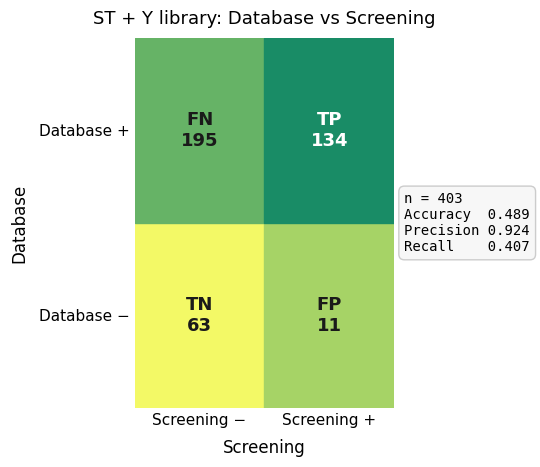

In [89]:
# ── Combined ST + Y ───────────────────────────────────────────────────────────
curr_df_all = pd.merge(
    dat_in_screen, train_dat_pos,
    left_on=['kinase_acc', 'substrate'],
    right_on=['kinase', 'substrate_seq_15aa']
)
curr_df_all['set'] = 'train_tn'
curr_df_all.loc[curr_df_all['y_true'] == 1, 'set'] = 'train_pos'

_, stats_all = plot_db_vs_screening_confusion(curr_df_all, title='ST + Y library: Database vs Screening')

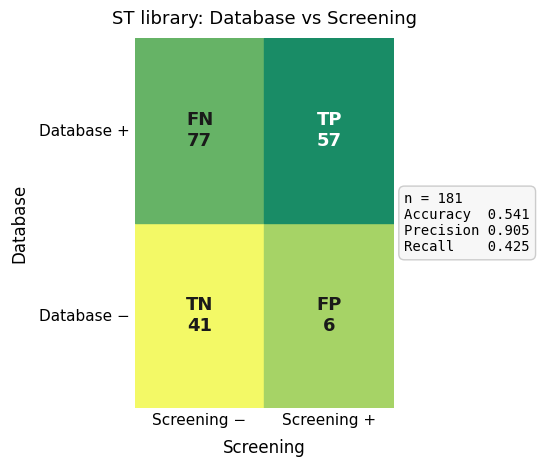

In [90]:
# ── ST library only ───────────────────────────────────────────────────────────
curr_df_st = curr_df_all.loc[curr_df_all['kinase_type'] == 'ST', :].copy()
_, stats_st = plot_db_vs_screening_confusion(curr_df_st, title='ST library: Database vs Screening')

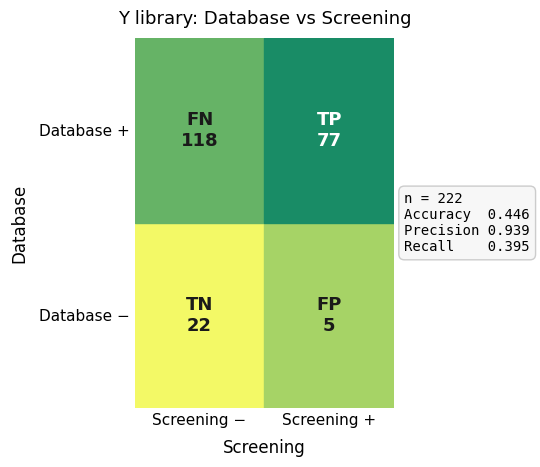

In [91]:
# ── Y library only ────────────────────────────────────────────────────────────
curr_df_y = curr_df_all.loc[curr_df_all['kinase_type'] != 'ST', :].copy()
_, stats_y = plot_db_vs_screening_confusion(curr_df_y, title='Y library: Database vs Screening')

### 7b. Confusion matrices — evaluable subset only

Same 2×2 layout but the **FN cell contains only evaluable false negatives**.
Non-evaluable pairs (FP substrate, inactive substrate, no PAABD motif, not in screen)
are removed from the DB+ denominator; their total count is shown in brackets inside
the FN cell and itemised in the figure footnote.


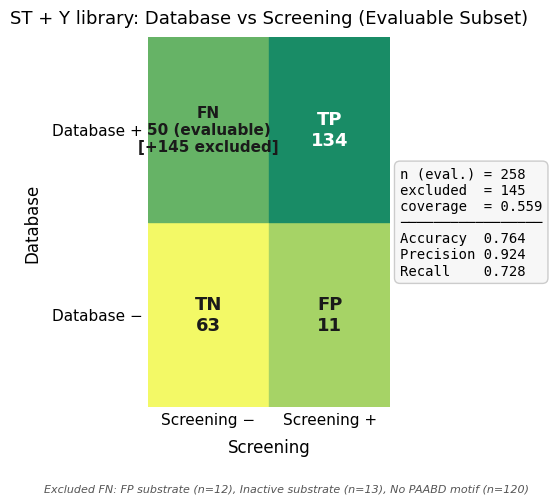

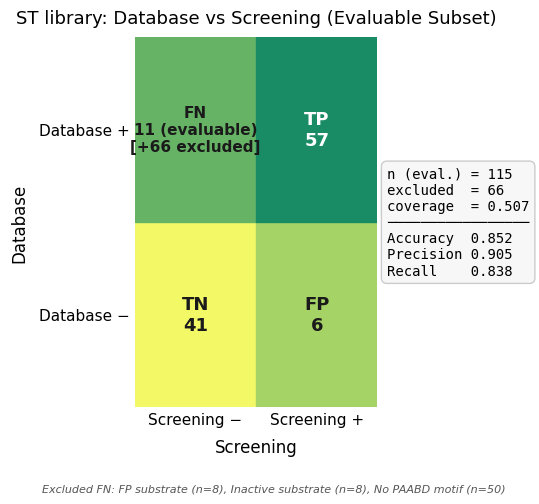

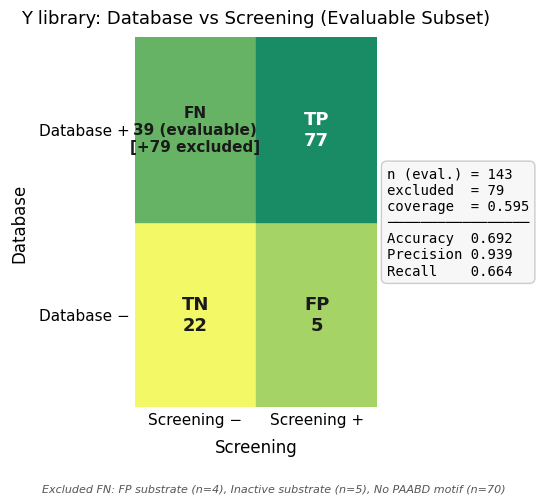

In [92]:
# ── Evaluable-subset confusion matrices ──────────────────────────────────────
# rec_y / rec_st / rec_all are produced in Section 8b; run that section first.

_, stats_eval_all = plot_db_vs_screening_confusion_evaluable(
    curr_df_all, rec_all,
    title='ST + Y library: Database vs Screening (Evaluable Subset)'
)

_, stats_eval_st = plot_db_vs_screening_confusion_evaluable(
    curr_df_st, rec_st,
    title='ST library: Database vs Screening (Evaluable Subset)'
)

_, stats_eval_y = plot_db_vs_screening_confusion_evaluable(
    curr_df_y, rec_y,
    title='Y library: Database vs Screening (Evaluable Subset)'
)


---
## 8. Evaluable-Subset Recall Analysis

The headline recall is deflated by annotated pairs that are biologically real but
**structurally invisible or experimentally invalid** in this assay.
We partition FN pairs into five mutually exclusive, priority-ordered categories:

| Priority | Category | Definition | Interpretation |
|---|---|---|---|
| 1 | **fp_sub** | Substrate flagged as a false positive (e.g., non-specific binder) | Invalid substrate — exclude from denominator |
| 2 | **Inactive substrate** | Substrate present in library but zero positive KSI calls across *all* kinases | Likely not functional in this screen context |
| 3 | **No PAABD** | Substrate lacks a canonical reader-domain motif (ST: 14-3-3 / WW / FHA; Y: SH2) | Outside assay detection mechanism |
| 4 | **Not in screen** | Substrate not recovered in the yeast screen at all | Below detection threshold / lost in production |
| 5 | **Evaluable FN** | None of the above — substrate is present, valid, active, and has a motif | True platform miss |

Recall is then recomputed removing non-evaluable pairs from the denominator,
and a DB+ coverage metric tracks what fraction of annotated pairs the platform can actually assess.


### 8a. Build non-evaluability flags for every FN pair

In [93]:
# ── Identify all FN pairs (DB+ but screen−) ────────────────────────────────
curr_df_fn    = curr_df_all.loc[
    (curr_df_all['set'] == 'train_pos') & (~curr_df_all['true_positive'].astype(bool)),
:].copy()
curr_df_fn_st = curr_df_fn.loc[curr_df_fn['kinase_type'] == 'ST', :].copy()
curr_df_fn_y  = curr_df_fn.loc[curr_df_fn['kinase_type'] != 'ST', :].copy()

print(f'Total FN pairs: {curr_df_fn.shape[0]}  '
      f'(ST={curr_df_fn_st.shape[0]}, Y={curr_df_fn_y.shape[0]})')

# ── Scenario 1 — substrate is a validated false positive ────────────────────
# fp_sub is a pre-computed boolean column in dat_in_screen / curr_df_all
# (substrate shown to be a non-specific binder or otherwise invalidated)
curr_df_fn_st['is_fp_sub'] = curr_df_fn_st['fp_sub'].astype(bool)
curr_df_fn_y ['is_fp_sub'] = curr_df_fn_y ['fp_sub'].astype(bool)

# ── Scenario 2 — substrate is inactive (zero positive KSIs across all kinases) 
# A substrate is 'inactive' if it appears in the screened library (ksi_df)
# but was never called positive for ANY kinase in the full screen.
def inactive_substrates(ksi_df_lib):
    """Return set of substrate sequences with zero true_positive calls."""
    if 'true_positive' not in ksi_df_lib.columns:
        # Fall back to pos|fdr threshold if true_positive not available on raw table
        # Adjust FDR threshold to match the criterion used in dat_in_screen
        hit_mask = ksi_df_lib['FDR'] < 0.1
    else:
        hit_mask = ksi_df_lib['true_positive'].astype(bool)
    active_subs  = set(ksi_df_lib.loc[hit_mask, 'substrate'].dropna())
    screened_subs = set(ksi_df_lib['substrate'].dropna())
    return screened_subs - active_subs   # substrates that never produced a hit

inactive_subs_st = inactive_substrates(ksi_df_st)
inactive_subs_y  = inactive_substrates(ksi_df_y)

curr_df_fn_st['in_screen']      = curr_df_fn_st['substrate_seq_15aa'].isin(set(ksi_df_st['substrate'].dropna()))
curr_df_fn_st['is_inactive_sub']= curr_df_fn_st['substrate_seq_15aa'].isin(inactive_subs_st)

curr_df_fn_y['in_screen']       = curr_df_fn_y['substrate_seq_15aa'].isin(set(ksi_df_y['substrate'].dropna()))
curr_df_fn_y['is_inactive_sub'] = curr_df_fn_y['substrate_seq_15aa'].isin(inactive_subs_y)

# ── PAABD motif flags ────────────────────────────────────────────────────────
curr_df_fn_st['has_paabd'] = (curr_df_fn_st['b14-3-3'] | curr_df_fn_st['WW'] | curr_df_fn_st['FHA'])
# Y: detectable ⟺ pY + hydrophobic at +3 (I/L/V/M) — updated SH2 motif
curr_df_fn_y ['has_paabd'] = curr_df_fn_y ['SH2'].astype(bool)

# ── Priority-ordered category assignment ────────────────────────────────────
# Each FN gets exactly ONE category (first matching rule wins)
def assign_fn_category(df):
    """Assign a mutually exclusive FN category by priority order."""
    cat = pd.Series('evaluable', index=df.index)           # default: evaluable
    cat[~df['in_screen']]                                   = 'not_in_screen'
    cat[df['in_screen'] & ~df['has_paabd']]                 = 'no_paabd'
    cat[df['in_screen'] &  df['has_paabd'] & df['is_inactive_sub']] = 'inactive_sub'
    cat[df['is_fp_sub']]                                    = 'fp_sub'   # highest priority
    return cat

curr_df_fn_st['fn_category'] = assign_fn_category(curr_df_fn_st)
curr_df_fn_y ['fn_category'] = assign_fn_category(curr_df_fn_y)

curr_df_fn_eval = pd.concat([curr_df_fn_st, curr_df_fn_y], ignore_index=True)

# Summary counts
print()
for lib, df in [('ST', curr_df_fn_st), ('Y', curr_df_fn_y), ('Combined', curr_df_fn_eval)]:
    print(f'{lib} FN breakdown:')
    print(df['fn_category'].value_counts().to_string())
    print()

Total FN pairs: 195  (ST=77, Y=118)

ST FN breakdown:
fn_category
no_paabd        50
evaluable       11
fp_sub           8
inactive_sub     8

Y FN breakdown:
fn_category
no_paabd        70
evaluable       39
inactive_sub     5
fp_sub           4

Combined FN breakdown:
fn_category
no_paabd        120
evaluable        50
inactive_sub     13
fp_sub           12



### 8b. Recompute recall — overall, and excluding each non-evaluable class

In [94]:
CATEGORY_ORDER = ['fp_sub', 'inactive_sub', 'no_paabd', 'not_in_screen', 'evaluable']
CATEGORY_LABELS = {
    'fp_sub':        'FP substrate',
    'inactive_sub':  'Inactive substrate',
    'no_paabd':      'No PAABD motif',
    'not_in_screen': 'Not in screen',
    'evaluable':     'Evaluable FN',
}
NON_EVALUABLE = ['fp_sub', 'inactive_sub', 'no_paabd', 'not_in_screen']


def evaluable_recall(curr_df_lib, fn_eval_df, lib_label):
    """
    Compute recall at two levels:
      - overall         : TP / (TP + all FN)
      - evaluable only  : TP / (TP + evaluable FN)
    Also returns per-category FN counts and DB+ coverage.
    """
    db_pos   = curr_df_lib.loc[curr_df_lib['set'] == 'train_pos']
    TP_total = int(db_pos['true_positive'].astype(bool).sum())
    FN_total = int((~db_pos['true_positive'].astype(bool)).sum())

    cat_counts = fn_eval_df['fn_category'].value_counts()
    FN_eval    = int(cat_counts.get('evaluable', 0))
    FN_non     = FN_total - FN_eval

    recall_overall   = TP_total / (TP_total + FN_total) if (TP_total + FN_total) else float('nan')
    recall_evaluable = TP_total / (TP_total + FN_eval)  if (TP_total + FN_eval)  else float('nan')
    coverage         = (TP_total + FN_eval) / (TP_total + FN_total) if (TP_total + FN_total) else float('nan')

    print(f'─── {lib_label} ───')
    print(f'  TP                      : {TP_total}')
    print(f'  FN total                : {FN_total}')
    for cat in CATEGORY_ORDER:
        n = int(cat_counts.get(cat, 0))
        tag = '← evaluable' if cat == 'evaluable' else ''
        print(f'    {CATEGORY_LABELS[cat]:<22}: {n:>4}  {tag}')
    print(f'  DB+ coverage            : {coverage:.3f}')
    print(f'  Recall (overall)        : {recall_overall:.3f}')
    print(f'  Recall (evaluable)      : {recall_evaluable:.3f}')
    print()

    result = {
        'library': lib_label,
        'TP': TP_total, 'FN_total': FN_total,
        'FN_evaluable': FN_eval,
    }
    for cat in CATEGORY_ORDER:
        result[f'FN_{cat}'] = int(cat_counts.get(cat, 0))
    result['db_coverage']       = round(coverage, 3)
    result['recall_overall']    = round(recall_overall, 3)
    result['recall_evaluable']  = round(recall_evaluable, 3)
    return result


fn_eval_y  = curr_df_fn_eval.loc[curr_df_fn_eval['kinase_type'] != 'ST']
fn_eval_st = curr_df_fn_eval.loc[curr_df_fn_eval['kinase_type'] == 'ST']

rec_y   = evaluable_recall(curr_df_y,   fn_eval_y,          'Y library')
rec_st  = evaluable_recall(curr_df_st,  fn_eval_st,         'ST library')
rec_all = evaluable_recall(curr_df_all, curr_df_fn_eval,    'Combined')


─── Y library ───
  TP                      : 77
  FN total                : 118
    FP substrate          :    4  
    Inactive substrate    :    5  
    No PAABD motif        :   70  
    Not in screen         :    0  
    Evaluable FN          :   39  ← evaluable
  DB+ coverage            : 0.595
  Recall (overall)        : 0.395
  Recall (evaluable)      : 0.664

─── ST library ───
  TP                      : 57
  FN total                : 77
    FP substrate          :    8  
    Inactive substrate    :    8  
    No PAABD motif        :   50  
    Not in screen         :    0  
    Evaluable FN          :   11  ← evaluable
  DB+ coverage            : 0.507
  Recall (overall)        : 0.425
  Recall (evaluable)      : 0.838

─── Combined ───
  TP                      : 134
  FN total                : 195
    FP substrate          :   12  
    Inactive substrate    :   13  
    No PAABD motif        :  120  
    Not in screen         :    0  
    Evaluable FN          :   50  ← eva

### 8c. Stacked-bar visualisation: DB+ pair decomposition

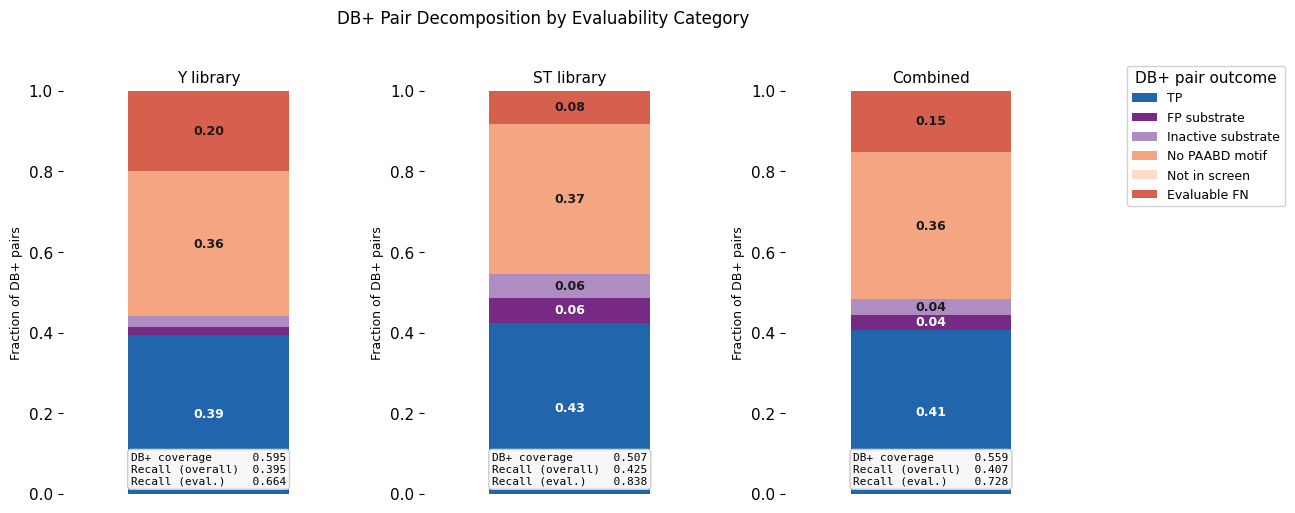

Saved: fn_decomposition_stacked_bar.pdf


In [96]:
CAT_COLORS = {
    'TP':            '#2166ac',   # strong blue
    'fp_sub':        '#762a83',   # purple   — invalid substrate
    'inactive_sub':  '#af8dc3',   # light purple — inactive in screen
    'no_paabd':      '#f4a582',   # light orange — no motif
    'not_in_screen': '#fddbc7',   # pale orange  — absent from library
    'evaluable':     '#d6604d',   # medium red   — true platform miss
}

STACK_ORDER = ['TP', 'fp_sub', 'inactive_sub', 'no_paabd', 'not_in_screen', 'evaluable']
STACK_LABELS = {
    'TP':            'TP',
    'fp_sub':        'FP substrate',
    'inactive_sub':  'Inactive substrate',
    'no_paabd':      'No PAABD motif',
    'not_in_screen': 'Not in screen',
    'evaluable':     'Evaluable FN',
}

fig, axes = plt.subplots(1, 3, figsize=(11, 5), sharey=False)

for ax, res in zip(axes, [rec_y, rec_st, rec_all]):
    total_db_pos = res['TP'] + res['FN_total']
    fracs = {'TP': res['TP'] / total_db_pos}
    for cat in NON_EVALUABLE:
        fracs[cat] = res[f'FN_{cat}'] / total_db_pos
    fracs['evaluable'] = res['FN_evaluable'] / total_db_pos

    bottom = 0.0
    for key in STACK_ORDER:
        frac  = fracs[key]
        color = CAT_COLORS[key]
        ax.bar(0, frac, bottom=bottom, color=color, width=0.55, label=STACK_LABELS[key])
        if frac > 0.035:
            lum = _luminance(mcolors.to_rgba(color))
            txt_col = 'white' if lum < 0.45 else '#1a1a1a'
            ax.text(0, bottom + frac / 2, f'{frac:.2f}',
                    ha='center', va='center', fontsize=9,
                    color=txt_col, fontweight='bold')
        bottom += frac

    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.set_title(res['library'], fontsize=11)
    ax.set_ylabel('Fraction of DB+ pairs', fontsize=9)
    ax.annotate(
        f"DB+ coverage      {res['db_coverage']:.3f}\n"
        f"Recall (overall)  {res['recall_overall']:.3f}\n"
        f"Recall (eval.)    {res['recall_evaluable']:.3f}",
        xy=(0.5, 0.02), xycoords='axes fraction',
        fontsize=8, fontfamily='monospace', va='bottom', ha='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#f7f7f7', edgecolor='#cccccc')
    )
    for spine in ax.spines.values():
        spine.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=9, framealpha=0.9,
           title='DB+ pair outcome', bbox_to_anchor=(1.18, 0.92))
fig.suptitle('DB+ Pair Decomposition by Evaluability Category', fontsize=12, y=1.02)
plt.tight_layout()
# plt.savefig('./fn_decomposition_stacked_bar.pdf', bbox_inches='tight')
plt.show()
print('Saved: fn_decomposition_stacked_bar.pdf')


### 8d. Incremental recall: effect of removing each non-evaluable class

In [97]:
def incremental_recall_table(res, fn_df_lib, lib_label):
    """
    Show how recall improves as each non-evaluable class is progressively
    removed from the denominator, in priority order.
    """
    TP = res['TP']
    rows = []
    current_fn = fn_df_lib.copy()

    # Baseline: all FN included
    recall = TP / (TP + len(current_fn)) if (TP + len(current_fn)) else float('nan')
    rows.append({'Step': 'Baseline (all DB+ pairs)', 'Removed': '—',
                 'n_removed': 0, 'FN_remaining': len(current_fn),
                 'Recall': round(recall, 3)})

    for cat in NON_EVALUABLE:
        mask      = current_fn['fn_category'] == cat
        n_removed = int(mask.sum())
        current_fn = current_fn.loc[~mask]
        recall    = TP / (TP + len(current_fn)) if (TP + len(current_fn)) else float('nan')
        rows.append({
            'Step':          f'− {CATEGORY_LABELS[cat]}',
            'Removed':       CATEGORY_LABELS[cat],
            'n_removed':     n_removed,
            'FN_remaining':  len(current_fn),
            'Recall':        round(recall, 3),
        })

    tbl = pd.DataFrame(rows)
    print(f'\n── {lib_label} ──')
    print(tbl.to_string(index=False))
    return tbl


tbl_y   = incremental_recall_table(rec_y,   fn_eval_y,   'Y library')
tbl_st  = incremental_recall_table(rec_st,  fn_eval_st,  'ST library')
tbl_all = incremental_recall_table(rec_all, curr_df_fn_eval, 'Combined')



── Y library ──
                    Step            Removed  n_removed  FN_remaining  Recall
Baseline (all DB+ pairs)                  —          0           118   0.395
          − FP substrate       FP substrate          4           114   0.403
    − Inactive substrate Inactive substrate          5           109   0.414
        − No PAABD motif     No PAABD motif         70            39   0.664
         − Not in screen      Not in screen          0            39   0.664

── ST library ──
                    Step            Removed  n_removed  FN_remaining  Recall
Baseline (all DB+ pairs)                  —          0            77   0.425
          − FP substrate       FP substrate          8            69   0.452
    − Inactive substrate Inactive substrate          8            61   0.483
        − No PAABD motif     No PAABD motif         50            11   0.838
         − Not in screen      Not in screen          0            11   0.838

── Combined ──
                    Step 

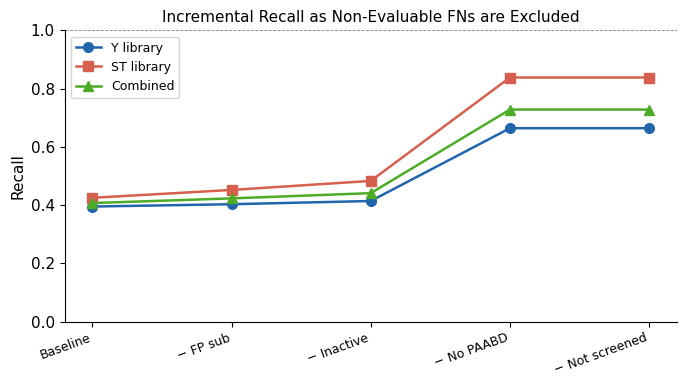

Saved: incremental_recall_stepplot.pdf


In [98]:
# Step-plot: recall trajectory as non-evaluable classes are removed
fig, ax = plt.subplots(figsize=(7, 4))

line_styles = ['-o', '-s', '-^']
line_colors = ['#2166ac', '#d6604d', '#4dac26']

for (tbl, label, ls, lc) in zip(
    [tbl_y, tbl_st, tbl_all],
    ['Y library', 'ST library', 'Combined'],
    line_styles, line_colors
):
    ax.plot(range(len(tbl)), tbl['Recall'], ls, color=lc,
            label=label, linewidth=1.8, markersize=7)

step_labels = ['Baseline', '− FP sub', '− Inactive', '− No PAABD', '− Not screened']
ax.set_xticks(range(len(step_labels)))
ax.set_xticklabels(step_labels, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Recall', fontsize=11)
ax.set_title('Incremental Recall as Non-Evaluable FNs are Excluded', fontsize=11)
ax.legend(fontsize=9)
ax.set_ylim(0, 1)
ax.axhline(1.0, color='grey', linewidth=0.6, linestyle='--')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
# plt.savefig('./incremental_recall_stepplot.pdf', bbox_inches='tight')
plt.show()
print('Saved: incremental_recall_stepplot.pdf')


### 8e. FN decomposition table and evaluable-subset confusion matrices

In [99]:
# ── Table: TP / FP / TN / FN breakdown per library ─────────────────────────
rows = []
for label, curr_df_lib, rec in [
    ('Y library',  curr_df_y,   rec_y),
    ('ST library', curr_df_st,  rec_st),
    ('Combined',   curr_df_all, rec_all),
]:
    db_pos = curr_df_lib.loc[curr_df_lib['set'] == 'train_pos']
    TP = int(db_pos['true_positive'].astype(bool).sum())
    FP = int((curr_df_lib['true_positive'].astype(bool) & curr_df_lib['set'].eq('train_tn')).sum())
    TN = int((~curr_df_lib['true_positive'].astype(bool) & curr_df_lib['set'].eq('train_tn')).sum())
    rows.append({
        'Library':              label,
        'TP':                   TP,
        'FP':                   FP,
        'TN':                   TN,
        'FN (total)':           rec['FN_total'],
        '  ↳ FP substrate':     rec['FN_fp_sub'],
        '  ↳ Inactive sub':     rec['FN_inactive_sub'],
        '  ↳ No PAABD':         rec['FN_no_paabd'],
        '  ↳ Not in screen':    rec['FN_not_in_screen'],
        '  ↳ Evaluable FN':     rec['FN_evaluable'],
        'Precision':            rec['recall_overall'],   # placeholder — recalc below
        'Recall (overall)':     rec['recall_overall'],
        'Recall (evaluable)':   rec['recall_evaluable'],
    })

fn_table = pd.DataFrame(rows)
# Recalculate precision from raw counts
fn_table['Precision'] = fn_table.apply(
    lambda r: round(r['TP'] / (r['TP'] + r['FP']), 3) if (r['TP'] + r['FP']) else float('nan'),
    axis=1
)

fn_table.style \
    .set_caption('FN Decomposition and Evaluable-Subset Metrics') \
    .background_gradient(
        subset=['Precision', 'Recall (overall)', 'Recall (evaluable)'],
        cmap='Blues'
    ) \
    .format({
        'Precision':           '{:.3f}',
        'Recall (overall)':    '{:.3f}',
        'Recall (evaluable)':  '{:.3f}',
    }) \
    .hide(axis='index')


Library,TP,FP,TN,FN (total),↳ FP substrate,↳ Inactive sub,↳ No PAABD,↳ Not in screen,↳ Evaluable FN,Precision,Recall (overall),Recall (evaluable)
Y library,77,5,22,118,4,5,70,0,39,0.939,0.395,0.664
ST library,57,6,41,77,8,8,50,0,11,0.905,0.425,0.838
Combined,134,11,63,195,12,13,120,0,50,0.924,0.407,0.728


In [104]:
fn_table.columns = ['Library', 'TP', 'FP', 'TN', 'FN (total)', 'FP sub',
       'Inactive sub', 'No PAABD', '  ↳ Not in screen',
       'Evaluable FN', 'Precision', 'Recall (overall)',
       'Recall (evaluable)']

In [110]:
fn_table = fn_table.loc[:,['Library', 'TP', 'FP', 'TN', 'FN (total)', 'FP sub',
       'Inactive sub', 'No PAABD',
       'Evaluable FN', 'Precision',
       'Recall (evaluable)']]

In [111]:
fn_table.columns = ['Library', 'TP', 'FP', 'TN', 'FN (total)', 'FP sub',
       'Inactive sub', 'No PAABD',
       'FN (evaluable)', 'Precision',
       'Recall']

In [112]:
fn_table

,Library,TP,FP,TN,FN (total),FP sub,Inactive sub,No PAABD,FN (evaluable),Precision,Recall
0,Y library,77,5,22,118,4,5,70,39,0.939,0.664
1,ST library,57,6,41,77,8,8,50,11,0.905,0.838
2,Combined,134,11,63,195,12,13,120,50,0.924,0.728


In [118]:
fn_table.to_latex()

'\\begin{tabular}{llrrrrrrrrrr}\n\\toprule\n & Library & TP & FP & TN & FN (total) & FP sub & Inactive sub & No PAABD & FN (evaluable) & Precision & Recall \\\\\n\\midrule\n0 & Y library & 77 & 5 & 22 & 118 & 4 & 5 & 70 & 39 & 0.939000 & 0.664000 \\\\\n1 & ST library & 57 & 6 & 41 & 77 & 8 & 8 & 50 & 11 & 0.905000 & 0.838000 \\\\\n2 & Combined & 134 & 11 & 63 & 195 & 12 & 13 & 120 & 50 & 0.924000 & 0.728000 \\\\\n\\bottomrule\n\\end{tabular}\n'

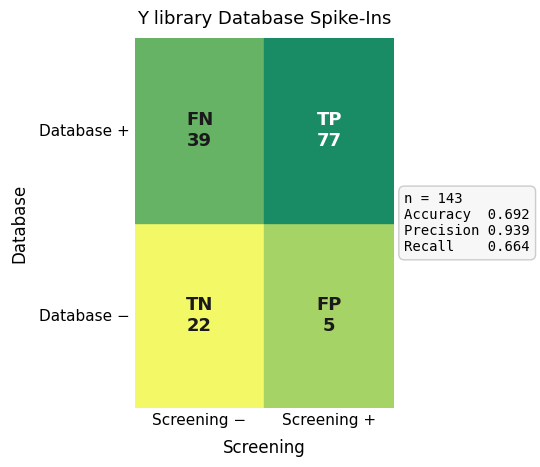

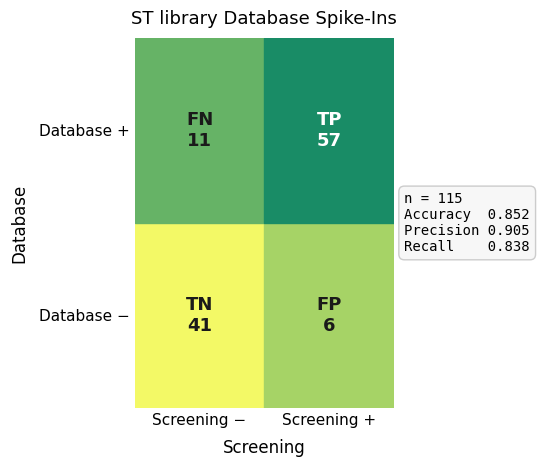

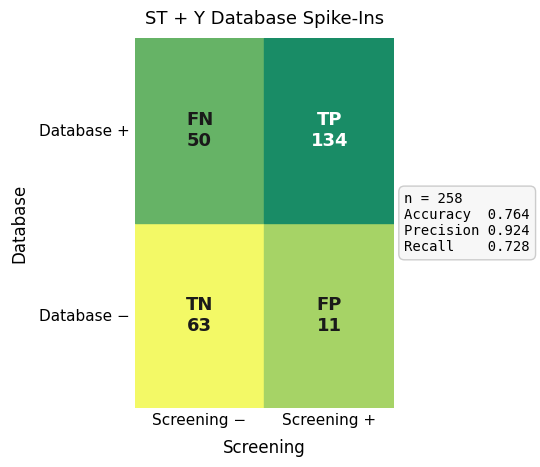

In [117]:
# ── Evaluable-subset confusion matrices ──────────────────────────────────────
# Drop non-evaluable FN rows from each library DataFrame using the pair key
# (index-based drop is unsafe because curr_df_fn_eval was reset after concat).

PAIR_KEYS = ['kinase_acc', 'substrate_seq_15aa']

def make_evaluable_df(curr_df_lib, fn_eval_df_lib):
    """
    Return curr_df_lib with non-evaluable FN rows removed.
    Rows are matched on PAIR_KEYS to avoid index-mismatch after concat resets.
    """
    non_eval_pairs = fn_eval_df_lib.loc[
        fn_eval_df_lib['fn_category'] != 'evaluable', PAIR_KEYS
    ]
    exclude_mask = curr_df_lib.set_index(PAIR_KEYS).index.isin(
        pd.MultiIndex.from_frame(non_eval_pairs)
    )
    return curr_df_lib.loc[~exclude_mask]

df_eval_y   = make_evaluable_df(curr_df_y,   curr_df_fn_eval.loc[curr_df_fn_eval['kinase_type'] != 'ST'])
df_eval_st  = make_evaluable_df(curr_df_st,  curr_df_fn_eval.loc[curr_df_fn_eval['kinase_type'] == 'ST'])
df_eval_all = make_evaluable_df(curr_df_all, curr_df_fn_eval)

_, stats_eval_y   = plot_db_vs_screening_confusion(
    df_eval_y,   title='Y library Database Spike-Ins',fname="confusion_matrix_y")
_, stats_eval_st  = plot_db_vs_screening_confusion(
    df_eval_st,  title='ST library Database Spike-Ins',fname="confusion_matrix_st")
_, stats_eval_all = plot_db_vs_screening_confusion(
    df_eval_all, title='ST + Y Database Spike-Ins',fname="confusion_matrix_sty")